# 2. Constrained Dynamics

Curvilinear coordinates such as bond angles and Euler angles have coordinate singularities,
where the transformation from Cartesian coordinates breaks down.

PySCIVR avoids this problem by propagating the dynamics in redundant coordinates with holonomic
constraints (SHAKE/RATTLE), and transforms to the curvilinear coordinates only in the analysis,
away from the singularities.

First, the pure rotation of H2 is used as an example:

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (6 DOFs) with 4 constraints (bond and 3 translations) | `H2SplinePotential` | `ShakeRattle` | 2D sphere (polar $\theta$ and azimuthal angle $\phi$) |

- The bond length and the center of mass are fixed by constraints.
- The molecule rotates through the z-axis ($\theta = 0, \pi$), where the azimuthal angle $\phi$ is undefined.
- `H2SplinePotential` is used as the potential.
- The trajectory is saved and loaded.

> **Note:** For the pure rotation, the potential energy is constant, since it depends only on the shape of the molecule, which is fixed by the constraints. A constant potential affects neither the trajectory nor the monodromy matrix, so `ZeroPotential` gives the same results. Here, `H2SplinePotential` is used for consistency with the ro-vibration below.

In [1]:
# import necessary libraries

import numpy as np
import matplotlib.pyplot as plt
 
from pyscivr.coordinates import InternalCoordinates
from pyscivr.integrators import ShakeRattle
from pyscivr.potentials import H2SplinePotential
from pyscivr.save import load_trajectory, save_trajectory
from pyscivr.units import CmInv, FemtoSec

## Set system

H2 is placed along the x-axis at the equilibrium bond length ($r_e = 0.74160392 \AA$).

In [2]:
mass = np.array([1.008, 1.008]) # mass of hydrogen atoms [amu (atomic mass unit)]
r_e = 0.74160392 # equilibrium bond length [Angs]
posi_ref = np.array([[-r_e / 2, 0.0, 0.0], [r_e / 2, 0.0, 0.0]])

calc = H2SplinePotential()
ener, force = calc.energy_forces(posi_ref)

print(f"Energy: {ener:.10f} eV")
print(f"Maximum force: {np.max(np.abs(force)):.10f} eV/Å")

Energy: -31.9530315756 eV
Maximum force: 0.0000001025 eV/Å


## Set constraints

H2 has 6 Cartesian DOFs. We fix the center of mass (3 constraints) and the bond length (1 constraint), leaving 2 rotational DOFs.

Coordinates are defined by `InternalCoordinates` in the following steps:

1. Create an `InternalCoordinates` object with the reference positions `posi_ref` and the masses.

2. Add coordinates by the `add_*` methods, e.g. `add_translation()` for the center of mass and `add_bond(i, j)` for the bond length between atoms `i` and `j`. Bond angles, dihedral angles, polar and azimuthal angles, and Euler angles can be added in the same way.

3. Call `build()` to finalize the coordinate system.

When used as constraints, each coordinate is fixed to its value at the reference positions `posi_ref`, i.e., the constraint is $F(q) = Q(q) - Q(q_{\text{ref}}) = 0$.

Here, the bond length is fixed to the equilibrium bond length `r_e`, and the center of mass is fixed to that of `posi_ref`.

All coordinates in `coord_const` are treated as constraints by `ShakeRattle`.

See [`pyscivr.coordinates`](https://tsumura-m.github.io/PySCIVR/pyscivr.coordinates.html) for the full list of coordinates.

In [3]:
coord_const = InternalCoordinates(posi_ref, mass) # Initialize internal coordinates
coord_const.add_translation()
coord_const.add_bond(0, 1)
coord_const.build()
print(coord_const) # Prints the internal coordinates and their reference values

Build complete: 4 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: bond(0, 1)      value_ref=0.741604


## Set initial conditions

The trajectory starts from the reference positions `posi_ref`: the molecule lies along the x-axis at the equilibrium bond length `r_e`, with the center of mass at the origin.

Since the constraints are defined at `posi_ref`, the initial positions satisfy them exactly. (`ShakeRattle` raises an error if the initial positions do not satisfy the constraints.)

The atoms are given opposite momenta perpendicular to the bond, so that the total momentum is zero and the bond length does not change, i.e., the initial momenta are also consistent with the constraints.

The molecule then rotates rigidly with the rotational kinetic energy `K_rot` $\text{cm}^{-1}$.

`tilt` is the angle of the rotation plane from the xy-plane: with `tilt = 0`, the molecule rotates in the xy-plane and never passes through the z-axis, while with `tilt = pi / 2`, it rotates in the xz-plane and passes through the z-axis ($\theta = 0, \pi$) twice per rotation.

In [4]:
def initial_momenta(K_rot, K_vib, tilt):
    """Momenta for rigid rotation with the rotational kinetic energy K_rot [cm^-1] and vibrational kinetic energy K_vib [cm^-1]."""
    p_rot = np.sqrt(K_rot * CmInv * mass[0])
    p_vib = np.sqrt(K_vib * CmInv * mass[0])
    p_rot_y = p_rot * np.cos(tilt)
    p_rot_z = p_rot * np.sin(tilt)
    return np.array([[-p_vib, -p_rot_y, -p_rot_z], [p_vib, p_rot_y, p_rot_z]])
 
mome_init = initial_momenta(K_rot=2000, K_vib=0, tilt=np.pi/2)

## Running the dynamics

The dynamics is propagated by [`ShakeRattle`](https://tsumura-m.github.io/PySCIVR/pyscivr.integrators.html#pyscivr.integrators.ShakeRattle), which takes the potential, the initial positions and momenta, the masses, the time step, and the constraints `coord_const`.

- **The time step must be given in the internal time unit**; here it is converted from fs by multiplying `FemtoSec`.
- `run(n_step)` returns the trajectory as a dictionary of arrays. The initial state is included, so each array has `n_step + 1` steps.
- In addition to the positions, momenta, forces and energies, the trajectory contains the Lagrange multipliers `lam` and `mu` of the constraints, which are needed for the propagation of the variations in the later tutorial.

The convergence of SHAKE can be controlled by the keyword arguments `max_iter_shake` and `tol_shake` (see the API reference).

In [5]:
dt_fs = 0.1 # time step in femtoseconds 
n_step = 5000

dt = dt_fs * FemtoSec # time step in internal units (Angs * sqrt(amu / eV))
 
dyn = ShakeRattle(calc, posi_ref, mome_init, mass, dt, coord_const)
traj = dyn.run(n_step)
t_fs = dt_fs * np.arange(n_step + 1)

print(traj.keys())

dict_keys(['posi', 'mome', 'potential_energy', 'force', 'total_energy', 'lam', 'mu', 'n_iter_shake', 'err_shake', 'dt', 'mass'])


## Check energy conservation and constraint error

The total energy is conserved, and the constraints are satisfied within the SHAKE tolerance at every step.

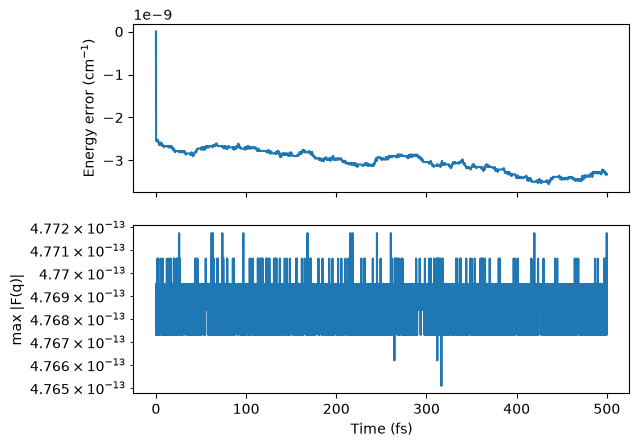

In [6]:
ener = traj["total_energy"]
 
fig, axes = plt.subplots(2, 1, sharex=True)
axes[0].plot(t_fs, (ener - ener[0]) / CmInv)
axes[0].set_ylabel("Energy error (cm$^{-1}$)")
axes[1].semilogy(t_fs[1:], traj["err_shake"][1:])
axes[1].set_ylabel("max |F(q)|")
axes[1].set_xlabel("Time (fs)")
plt.show()

## Save and load

If calculating trajectories is computationally expensive, they should be saved for reuse.

`save_trajectory` saves the positions, momenta, forces and energies.

The Lagrange multipliers `lam` and `mu` are not saved to reduce the file size, but can be restored from the trajectory by passing `coord_const` to `load_trajectory`.

The same constraints as used in the dynamics must be given; otherwise, the restoration fails with an error.

See [`pyscivr.save`](https://tsumura-m.github.io/PySCIVR/pyscivr.save.html) for details.

In [7]:
save_trajectory("h2_rot_pi2_traj.npz", traj)
traj_loaded = load_trajectory("h2_rot_pi2_traj.npz", coord_const=coord_const)

# Check if the saved and loaded trajectories are consistent
print("max |lam - lam_restored| =", np.max(np.abs(traj["lam"] - traj_loaded["lam"])))
print("max |mu - mu_restored|   =", np.max(np.abs(traj["mu"] - traj_loaded["mu"])))

max |lam - lam_restored| = 1.2248882463872235e-14
max |mu - mu_restored|   = 1.2241509889099333e-14


## Visualize the trajectory in the Cartesian coordinate

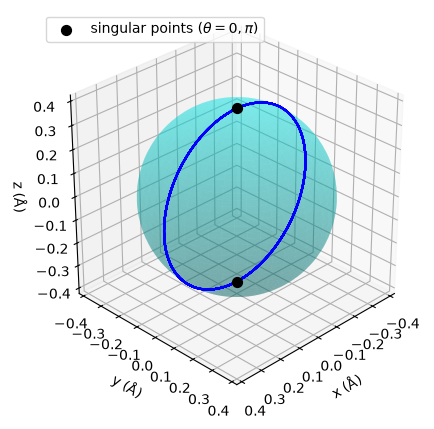

In [8]:
posi = traj_loaded["posi"]                                 # (T, N, 3)
radius = r_e / 2                                           # distance of each atom from the center of mass

U = np.linspace(0, 2 * np.pi, 100)
V = np.linspace(0, np.pi, 100)
X = radius * np.outer(np.cos(U), np.sin(V))
Y = radius * np.outer(np.sin(U), np.sin(V))
Z = radius * np.outer(np.ones(np.size(U)), np.cos(V))

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection='3d', computed_zorder=False)

ax.plot_surface(X, Y, Z, color='cyan', alpha=0.3, zorder=0)
ax.plot(posi[:, 0, 0], posi[:, 0, 1], posi[:, 0, 2], color='blue', zorder=1)
ax.scatter([0, 0], [0, 0], [radius, -radius], color='black', s=50, depthshade=False,
           label=r'singular points ($\theta = 0, \pi$)', zorder=2)
ax.set_xlabel("x (Å)")
ax.set_ylabel("y (Å)")
ax.set_zlabel("z (Å)")
ax.view_init(elev=30, azim=45)
ax.set_box_aspect((1, 1, 1))
ax.legend(loc="upper left")
plt.show()

## Convert to curvilinear coordinates

To analyze the rotation, we define a full set of 6 coordinates: the center of mass (3), the polar and azimuthal angles
of the bond (2), and the bond length (1).

The number of coordinates equals the number of Cartesian degrees of freedom ($3N = 6$), so that the transformation between the Cartesian and curvilinear coordinates can be inverted.

The row order is changed by `build()`, so the row indices are obtained by `find_coordinate`.

The coordinate values are obtained by `get_value(x)` for a single geometry, or by `get_value_batch(x)` for a batch,
where `x` is the flattened positions of shape `(3N,)` or `(T, 3N)`. The lengths are in Å and the angles are in radians.

Build complete: 6 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
    3: bond(0, 1)      value_ref=0.741604
    4: polar(0, 1)     value_ref=1.570796
    5: azimuthal(0, 1) value_ref=0.000000


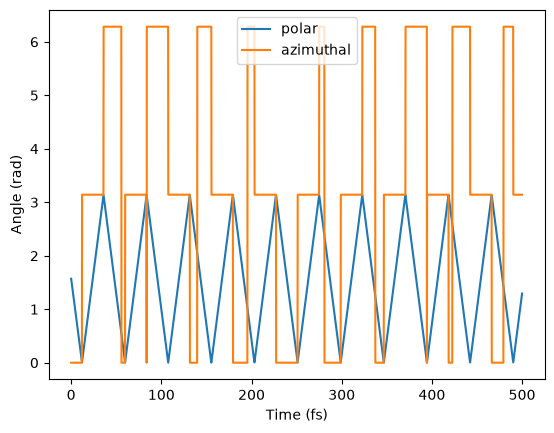

In [9]:
coord_all = InternalCoordinates(posi_ref, mass)
coord_all.add_translation()
coord_all.add_polar(0, 1)
coord_all.add_azimuthal(0, 1)
coord_all.add_bond(0, 1)
coord_all.build()
print(coord_all)
 
idx_polar = coord_all.find_coordinate("polar", (0, 1))[0]  # -> 4
idx_azim = coord_all.find_coordinate("azimuthal", (0, 1))[0]  #  -> 5
 
x = traj_loaded["posi"].reshape(n_step + 1, -1)  # (T, 3N)
values = np.asarray(coord_all.get_value_batch(x))  # (T, 6)
 
plt.plot(t_fs, values[:, idx_polar], label="polar")
plt.plot(t_fs, np.mod(values[:, idx_azim], 2 * np.pi), label="azimuthal")
plt.xlabel("Time (fs)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()

We can see that the azimuthal angle $\phi$ jumps by $\pi$ when the molecule crosses the z-axis ($\theta = 0, \pi$).

Exactly on the z-axis, $\phi$ is undefined, since every value of $\phi$ describes the same orientation (coordinate singularities).

The transformation from the Cartesian coordinates to $(\theta, \phi)$ therefore does not exist at these points,
and its derivatives diverge in their vicinity, as shown below.

## How to detect singularities

Whether the curvilinear coordinates $Q$ are well defined at a geometry $x$ can be checked by the gradient $B = \frac{\partial Q}{\partial x}$, which is a $3N \times 3N$ matrix for a full set of coordinates. The transformation can be inverted locally if and only if $B$ is nonsingular.

A simple way to identify coordinate singularities is to monitor the condition number of $B$,
i.e., the ratio of its largest to smallest singular values, along the trajectory.
The condition number diverges at a singularity, for either of two reasons:

- the smallest singular value goes to zero, i.e., the coordinates become linearly dependent, or
- the largest singular value diverges, i.e., the gradient of some coordinate diverges.

For the polar and azimuthal angles, the latter happens: the gradient of $\phi$ is proportional to $1 / \sin\theta$
and diverges on the z-axis.

On the other hand, the gradient $B_C$ of the constraints used in `ShakeRattle` (center of mass and bond length)
has no singularity along the trajectory, so the dynamics itself is not affected.

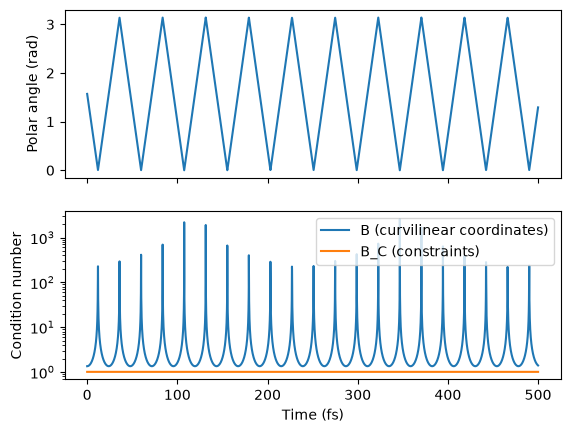

In [10]:
B_all = np.asarray(coord_all.get_const_grad_batch(x))     # (T, 6, 6)
B_const = np.asarray(coord_const.get_const_grad_batch(x))  # (T, 4, 6)
 
fig, axes = plt.subplots(2, 1, sharex=True)
axes[0].plot(t_fs, values[:, idx_polar])
axes[0].set_ylabel("Polar angle (rad)")
axes[1].semilogy(t_fs, np.linalg.cond(B_all), label="B (curvilinear coordinates)")
axes[1].semilogy(t_fs, np.linalg.cond(B_const), label="B_C (constraints)")
axes[1].set_ylabel("Condition number")
axes[1].set_xlabel("Time (fs)")
axes[1].legend()
plt.show()

The condition number of `B` diverges whenever the polar angle $\theta$ approaches $0$ or $\pi$, while that of `B_C` stays constant. Therefore, quantities that require the inverse of `B` should not be evaluated near these points e.g., the Hessian in the active coordinates by `eval_hess_active` (see the next tutorial).

## Compare with a trajectory not passing the singularities

With `tilt = pi / 4`, the rotation plane is tilted by 45° from the xy-plane, so the polar angle stays between $\pi / 4$ and $3 \pi / 4$ and the trajectory never passes through the poles.
The same `coord_const` and `coord_all` are used.

max energy error = 2.608e-09 cm^-1


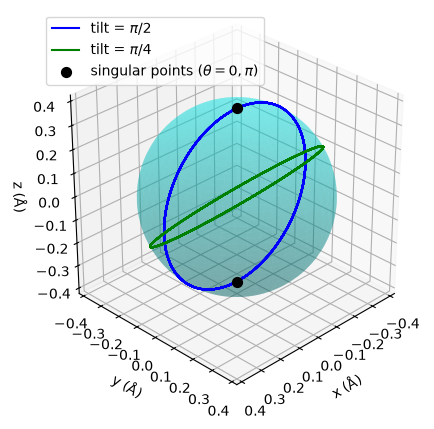

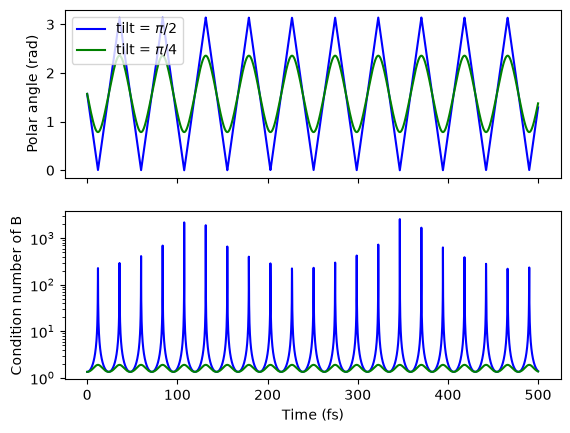

In [ ]:
mome_init_pi4 = initial_momenta(K_rot=2000, K_vib=0, tilt=np.pi / 4)
traj_pi4 = ShakeRattle(calc, posi_ref, mome_init_pi4, mass, dt, coord_const).run(n_step)

ener_pi4 = traj_pi4["total_energy"]
print(f"max energy error = {np.max(np.abs(ener_pi4 - ener_pi4[0])) / CmInv:.3e} cm^-1")

x_pi4 = traj_pi4["posi"].reshape(n_step + 1, -1)                 # (T, 3N)
values_pi4 = np.asarray(coord_all.get_value_batch(x_pi4))        # (T, 6)
B_all_pi4 = np.asarray(coord_all.get_const_grad_batch(x_pi4))    # (T, 6, 6)

radius = r_e / 2
U = np.linspace(0, 2 * np.pi, 100)
V = np.linspace(0, np.pi, 100)

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection='3d', computed_zorder=False)
ax.plot_surface(radius * np.outer(np.cos(U), np.sin(V)), radius * np.outer(np.sin(U), np.sin(V)),
                radius * np.outer(np.ones(np.size(U)), np.cos(V)), color='cyan', alpha=0.3, zorder=0)
ax.plot(*traj_loaded["posi"][:, 0].T, color='blue', label=r'tilt = $\pi/2$', zorder=1)
ax.plot(*traj_pi4["posi"][:, 0].T, color='green', label=r'tilt = $\pi/4$', zorder=1)
ax.scatter([0, 0], [0, 0], [radius, -radius], color='black', s=50, depthshade=False,
           label=r'singular points ($\theta = 0, \pi$)', zorder=2)
ax.set_xlabel("x (Å)")
ax.set_ylabel("y (Å)")
ax.set_zlabel("z (Å)")
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=30, azim=45)
ax.legend(loc="upper left")
plt.show()

fig, axes = plt.subplots(2, 1, sharex=True)
axes[0].plot(t_fs, values[:, idx_polar], color='blue', label=r'tilt = $\pi/2$')
axes[0].plot(t_fs, values_pi4[:, idx_polar], color='green', label=r'tilt = $\pi/4$')
axes[0].set_ylabel("Polar angle (rad)")
axes[0].legend()
axes[1].semilogy(t_fs, np.linalg.cond(B_all), color='blue')
axes[1].semilogy(t_fs, np.linalg.cond(B_all_pi4), color='green')
axes[1].set_ylabel("Condition number of B")
axes[1].set_xlabel("Time (fs)")
plt.show()

For `tilt = pi / 4`, the polar angle stays away from $0$ and $\pi$, and the condition number of $B$ remains bounded.

The two trajectories have the same rotational energy and are physically equivalent:
one is obtained from the other by rotating the whole system by $\pi / 4$ about the x-axis.
Nevertheless, only the trajectory with `tilt = pi / 2` passes through the singular points.
This shows that the coordinate singularity is not a physical property of the motion,
but an artifact of the choice of the curvilinear coordinates (here, the direction of the z-axis).
The dynamics in the redundant Cartesian coordinates is free from this artifact,
and both trajectories are propagated equally well.

Second, the ro-vibration of H2 is used as an example:

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (6 DOFs) with 3 constraints (3 translations) | H2SplinePotential | `ShakeRattle` | bond length $r$, polar $\theta$ and azimuthal angle $\phi$ |

- The center of mass is fixed by constraints.
- The molecule rotates through the z-axis ($\theta = 0, \pi$), where the azimuthal angle $\phi$ is undefined.
- The bond length is not constrained, so the molecule vibrates while rotating.

Build complete: 3 coordinates
InternalCoordinates:
    0: translation_x   value_ref=0.000000
    1: translation_y   value_ref=0.000000
    2: translation_z   value_ref=0.000000
max energy error = 4.062e+00 cm^-1


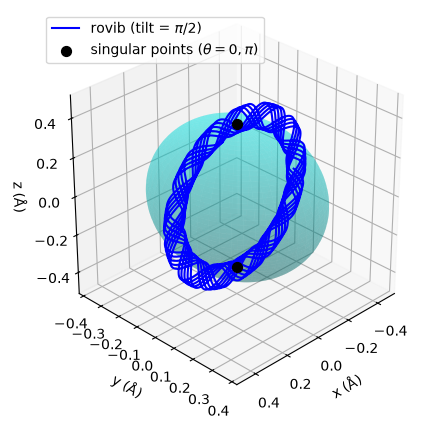

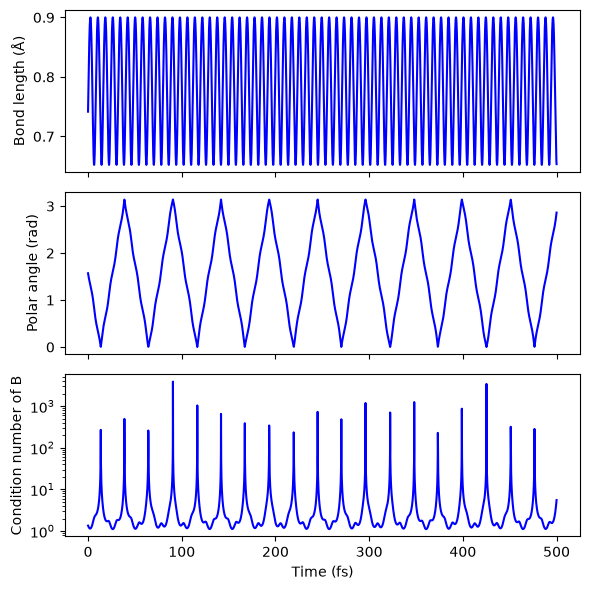

In [12]:
# Set constraints
coord_const_rovib = InternalCoordinates(posi_ref, mass)
coord_const_rovib.add_translation()
coord_const_rovib.build()
print(coord_const_rovib)

# set initial momenta
mome_init_rovib = initial_momenta(K_rot=2000, K_vib=2000, tilt=np.pi / 2)
traj_rovib = ShakeRattle(calc, posi_ref, mome_init_rovib, mass, dt, coord_const_rovib).run(n_step)

# check energy conservation
ener_rovib = traj_rovib["total_energy"]
print(f"max energy error = {np.max(np.abs(ener_rovib - ener_rovib[0])) / CmInv:.3e} cm^-1")

# save trajectory
save_trajectory("h2_rovib_pi2_traj.npz", traj_rovib)

# analyze trajectory
x_rovib = traj_rovib["posi"].reshape(n_step + 1, -1)                 # (T, 3N)
values_rovib = np.asarray(coord_all.get_value_batch(x_rovib))        # (T, 6)
B_all_rovib = np.asarray(coord_all.get_const_grad_batch(x_rovib))    # (T, 6, 6)


radius = r_e / 2
U = np.linspace(0, 2 * np.pi, 100)
V = np.linspace(0, np.pi, 100)

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection='3d', computed_zorder=False)
ax.plot_surface(radius * np.outer(np.cos(U), np.sin(V)), radius * np.outer(np.sin(U), np.sin(V)),
                radius * np.outer(np.ones(np.size(U)), np.cos(V)), color='cyan', alpha=0.3, zorder=0)
ax.plot(*traj_rovib["posi"][:, 0].T, color='blue', label=r'rovib (tilt = $\pi/2$)', zorder=1)
ax.scatter([0, 0], [0, 0], [radius, -radius], color='black', s=50, depthshade=False,
           label=r'singular points ($\theta = 0, \pi$)', zorder=2)
ax.set_xlabel("x (Å)")
ax.set_ylabel("y (Å)")
ax.set_zlabel("z (Å)")
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=30, azim=45)
ax.legend(loc="upper left")
plt.show()

bond_idx = coord_all.find_coordinate("bond", (0, 1))[0]  # -> 3

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(6, 6))
axes[0].plot(t_fs, values_rovib[:, bond_idx], color='blue')
axes[0].set_ylabel("Bond length (Å)")
axes[1].plot(t_fs, values_rovib[:, idx_polar], color='blue')
axes[1].set_ylabel("Polar angle (rad)")
axes[2].semilogy(t_fs, np.linalg.cond(B_all_rovib), color='blue')
axes[2].set_ylabel("Condition number of B")
axes[2].set_xlabel("Time (fs)")
plt.tight_layout()
plt.show()

- **Vibration**: The bond length oscillates between about 0.65 Å and 0.90 Å with a period of about 8 fs, consistent with the vibrational frequency of H2 (about 4200 $\text{cm}^{-1}$). The oscillation is asymmetric around $r_e$ (0.74 Å), reflecting the anharmonicity of the potential.
- **Rotation**: The polar angle shows small wiggles synchronized with the vibration. Since the angular momentum
  is conserved, the angular velocity decreases when the bond is stretched and increases when it is compressed.
  The rotational period (about 51 fs) is slightly longer than that of the pure rotation (about 48 fs),
  since the bond is longer on average.
- **Singularities**: The condition number of $B$ diverges whenever the polar angle approaches $0$ or $\pi$,
  as in the pure rotation. The coordinate singularities depend only on the orientation of the molecule,
  not on the vibration.
- **Trajectory on the sphere**: The atoms move inward and outward from the sphere of radius $r_e / 2$
  while rotating through the poles. Since the vibrational and rotational periods are incommensurate,
  the trajectory does not close after one rotation.